# Clustering FIFA 22 players, and checking how good my models really are

This is my project for the clustering and model evaluation module. The data is the FIFA 22 player database (`players_22.csv`, from Stefano Leone's Kaggle dataset, which was scraped from sofifa.com). It has about 19,000 players and 110 columns.

The notebook has two halves.

**Part A, clustering.** I group the players without telling the algorithm anything about them. I write K-Means by hand first, then check it against scikit-learn's version, then try hierarchical clustering and PCA.

**Part B, model evaluation.** Clustering has no "right answer" to score against, so I switch to a supervised problem to practice proper evaluation: cross-validation, confusion matrix, precision, recall, F1, ROC-AUC and hyperparameter tuning.

To run it, put `players_22.csv` in the same folder as this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, adjusted_rand_score, calinski_harabasz_score,
                             classification_report, confusion_matrix, davies_bouldin_score,
                             f1_score, roc_auc_score, roc_curve, silhouette_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize

SEED = 42

# plain, readable chart style (three colours that stay distinguishable for colour-blind readers)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
CLUSTER_COLORS = [BLUE, ORANGE, AQUA, "#eda100", "#e87ba4"]
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})

# Part A: Clustering

## 1. Loading the data and picking features

I'm clustering on five numbers that describe a player's level and market position: `overall`, `potential`, `wage_eur`, `value_eur` and `age`. A few players have missing wage or value, so I drop those rows. I also pass `low_memory=False` when reading the file, which stops pandas from complaining about mixed-type columns.

In [2]:
players = pd.read_csv("players_22.csv", low_memory=False)
print("Raw file:", players.shape)

features = ["overall", "potential", "wage_eur", "value_eur", "age"]
players = players.dropna(subset=features)
print("After dropping rows with missing wage/value:", players.shape)

raw = players[features].copy()      # keep the original units, I'll need them to explain the clusters
raw.describe().round(1)

Raw file: (19239, 110)
After dropping rows with missing wage/value: (19165, 110)


,overall,potential,wage_eur,value_eur,age
count,19165.0,19165.0,19165.0,19165.0,19165.0
mean,65.8,71.1,9021.7,2850451.8,25.2
std,6.9,6.1,19476.0,7613699.9,4.7
min,47.0,49.0,500.0,9000.0,16.0
25%,61.0,67.0,1000.0,475000.0,21.0
50%,66.0,71.0,3000.0,975000.0,25.0
75%,70.0,75.0,8000.0,2000000.0,29.0
max,93.0,95.0,350000.0,194000000.0,43.0


Wage and value look odd straight away: the mean is far above the median. Let me plot all five.

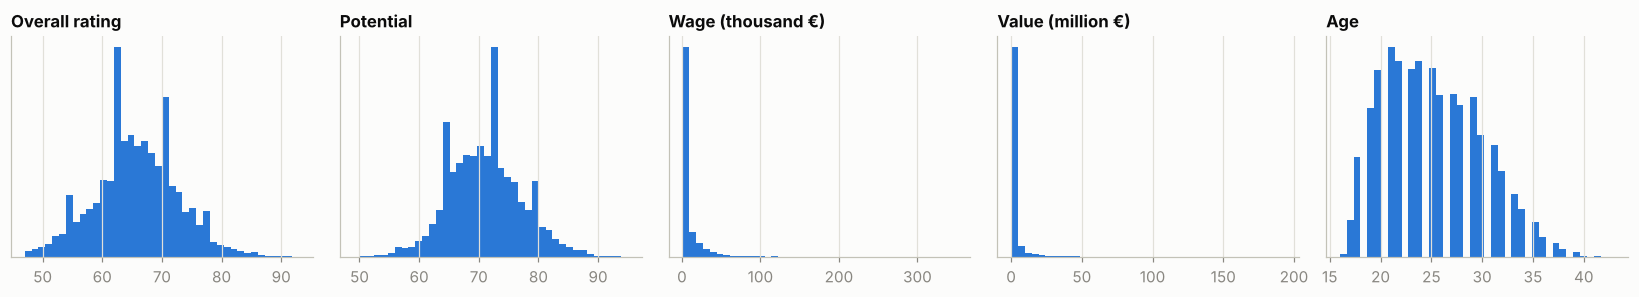

Skewness of each feature (0 = symmetric):
overall      0.08
potential    0.17
wage_eur     6.47
value_eur    8.19
age          0.41


In [3]:
fig, axes = plt.subplots(1, 5, figsize=(15, 2.8))
views = [("overall", "Overall rating", 1), ("potential", "Potential", 1),
         ("wage_eur", "Wage (thousand €)", 1e3), ("value_eur", "Value (million €)", 1e6), ("age", "Age", 1)]
for ax, (col, title, div) in zip(axes, views):
    ax.hist(raw[col] / div, bins=40, color=BLUE, linewidth=0)
    ax.set_title(title)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

print("Skewness of each feature (0 = symmetric):")
print(raw.skew().round(2).to_string())

Overall, potential and age look roughly bell-shaped. Wage and value do not. Most players earn very little and a handful of stars earn a huge amount, so those two features have a long tail to the right. I'll keep that in mind when I read the clusters.

## 2. Scaling

K-Means works with distances, so a feature measured in millions of euros would swamp one measured in years. I rescale every feature to the range 1 to 11. I use 1 to 11 instead of 0 to 1 because my centroid function (below) takes logs, and logs need numbers above zero.

In [4]:
data = ((raw - raw.min()) / (raw.max() - raw.min())) * 10 + 1
X = data.to_numpy()
data.describe().round(2)

,overall,potential,wage_eur,value_eur,age
count,19165.00,19165.00,19165.00,19165.00,19165.00
mean,5.08,5.80,1.24,1.15,4.40
std,1.50,1.32,0.56,0.39,1.75
min,1.00,1.00,1.00,1.00,1.00
25%,4.04,4.91,1.01,1.02,2.85
50%,5.13,5.78,1.07,1.05,4.33
75%,6.00,6.65,1.21,1.10,5.81
max,11.00,11.00,11.00,11.00,11.00


## 3. K-Means from scratch

The plan is the same one I wrote in my pseudocode:

1. Scale the data (done)
2. Pick random starting centroids
3. Give every player the label of its nearest centroid
4. Recompute each centroid from the players assigned to it
5. Repeat 3 and 4 until the centroids stop moving

The helper functions are my originals. I added a seed so random starts are repeatable, a guard in case a cluster ends up empty, and an SSE function (sum of squared distances to the assigned centroid) so I can measure how tight the clusters are.

One thing I noticed while tidying up: my `new_centroids` uses the **geometric mean** (`exp(mean(log(x)))`) instead of the ordinary mean. That is not what textbook K-Means does. The ordinary mean is the point that minimises squared distance, so it is the one that guarantees the SSE can only go down. I'm keeping my original version, but I added a switch so I can run both and see whether it matters.

In [5]:
def random_centroids(data, k, seed=None):
    """Each centroid takes one random value per feature (same idea as my original)."""
    rng = np.random.default_rng(seed)
    centroids = []
    for i in range(k):
        centroid = data.apply(lambda x: float(x.sample(random_state=int(rng.integers(1_000_000_000))).iloc[0]))
        centroids.append(centroid)
    return pd.concat(centroids, axis=1)


def get_labels(data, centroids):
    """Label = column of the closest centroid (Euclidean distance)."""
    distances = centroids.apply(lambda x: np.sqrt(((data - x) ** 2).sum(axis=1)))
    return distances.idxmin(axis=1)


def new_centroids(data, labels, k, how="geometric", previous=None):
    if how == "geometric":
        centroids = np.exp(np.log(data).groupby(labels).mean()).T     # my original version
    else:
        centroids = data.groupby(labels).mean().T                      # textbook K-Means
    centroids = centroids.reindex(columns=range(k))
    if previous is not None:                                           # empty cluster: keep the old centroid
        centroids = centroids.fillna(previous)
    return centroids


def sse(data, labels, centroids):
    assigned = centroids.T.loc[np.asarray(labels)].to_numpy()
    return float(((data.to_numpy() - assigned) ** 2).sum())


def kmeans_scratch(data, k, how="geometric", max_iterations=100, seed=0):
    centroids = random_centroids(data, k, seed)
    history = []
    for iteration in range(1, max_iterations + 1):
        labels = get_labels(data, centroids)
        history.append({"iteration": iteration, "labels": labels, "centroids": centroids,
                        "sse": sse(data, labels, centroids)})
        updated = new_centroids(data, labels, k, how, previous=centroids)
        converged = np.allclose(updated.to_numpy(), centroids.to_numpy(), atol=1e-9)
        centroids = updated
        if converged:
            break
    labels = get_labels(data, centroids)
    return {"labels": labels.to_numpy(), "centroids": centroids, "sse": sse(data, labels, centroids),
            "iterations": iteration, "history": history}

### Random starts matter

K-Means can settle into a poor solution depending on where the random centroids begin. I'll run my function from 10 different seeds, for both centroid types, and keep the run with the lowest SSE.

In [6]:
K = 3

runs = {how: [kmeans_scratch(data, K, how=how, seed=s) for s in range(10)] for how in ["geometric", "arithmetic"]}

seed_table = pd.DataFrame({
    ("SSE", "geometric (my original)"): [r["sse"] for r in runs["geometric"]],
    ("SSE", "arithmetic mean"):         [r["sse"] for r in runs["arithmetic"]],
    ("iterations", "geometric (my original)"): [r["iterations"] for r in runs["geometric"]],
    ("iterations", "arithmetic mean"):         [r["iterations"] for r in runs["arithmetic"]],
})
seed_table.index.name = "seed"
display(seed_table.round(1))

best = {how: min(rs, key=lambda r: r["sse"]) for how, rs in runs.items()}
for how, r in best.items():
    print(f"best {how:10s} run -> SSE {r['sse']:.1f} after {r['iterations']} iterations")

SSE                              iterations  \
     geometric (my original) arithmetic mean geometric (my original)   
seed                                                                   
0                    65779.0         63782.4                      24   
1                    65831.2         63782.3                      30   
2                    65779.0         63782.4                      28   
3                    65779.0         63782.5                      21   
4                    65779.0         63781.9                      15   
5                    65831.2         63782.4                      38   
6                    65831.2         63782.3                      36   
7                    65779.0         63781.9                      17   
8                    65829.4         63781.9                      10   
9                    65779.0         63782.4                      24   

                      
     arithmetic mean  
seed                  
0                 21  
1                 29  
2                 25  
3                 18  
4                 21  
5                 45  
6                 37  
7                 22  
8                 21  
9                 20

best geometric  run -> SSE 65779.0 after 24 iterations
best arithmetic run -> SSE 63781.9 after 21 iterations


### Watching it converge

First the pictures, then the numbers. I project the five scaled features down to two dimensions with PCA purely so I can draw them (PCA gets its own section later). Black crosses are the centroids. These are the first three iterations and the final one from my best run.

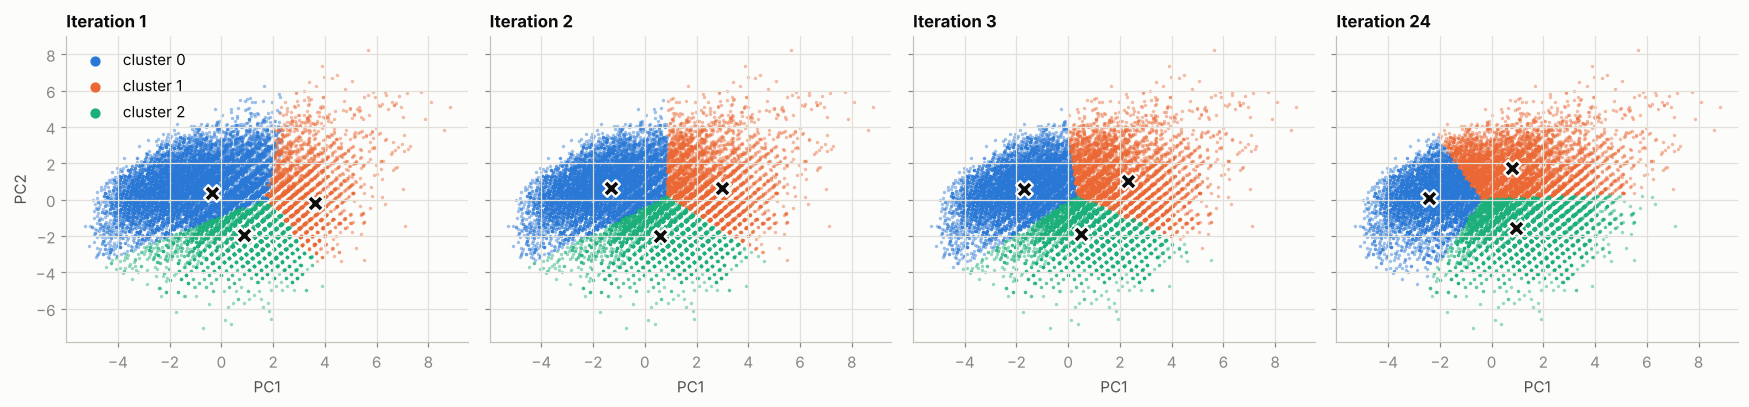

In [7]:
pca2d = PCA(n_components=2).fit(X)
points = pca2d.transform(X)


def draw_clusters(ax, labels, centroids, title):
    cents = pca2d.transform(centroids.T.to_numpy())
    for c in range(centroids.shape[1]):
        m = np.asarray(labels) == c
        ax.scatter(points[m, 0], points[m, 1], s=5, alpha=0.45, color=CLUSTER_COLORS[c], linewidths=0, label=f"cluster {c}")
    ax.scatter(cents[:, 0], cents[:, 1], marker="X", s=120, color=INK, edgecolor=SURFACE, linewidth=1.5, zorder=5)
    ax.set_title(title)
    ax.set_xlabel("PC1")


hist = best["geometric"]["history"]
shots = [hist[0], hist[1], hist[2], hist[-1]]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True, sharey=True)
for ax, h in zip(axes, shots):
    draw_clusters(ax, h["labels"], h["centroids"], f"Iteration {h['iteration']}")
axes[0].set_ylabel("PC2")
leg = axes[0].legend(loc="upper left")
for h in leg.legend_handles:
    h.set_sizes([45])
    h.set_alpha(1)
plt.tight_layout()
plt.show()

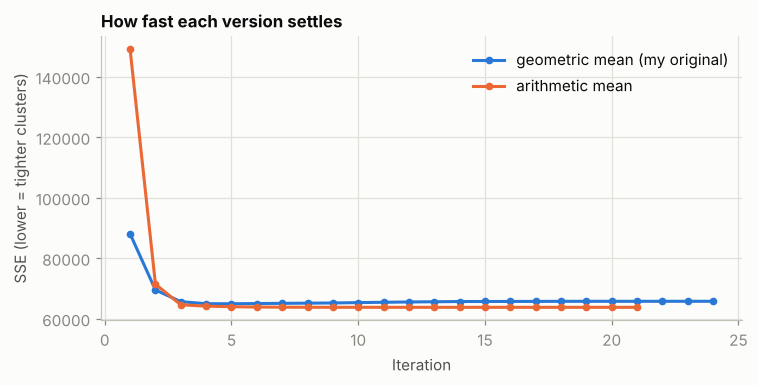

geometric : SSE 88073 -> 65779 (lowest 64963 at iteration 5), ever increased between iterations: True
arithmetic: SSE 149079 -> 63782 (lowest 63782 at iteration 21), ever increased between iterations: False


In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for how, color, name in [("geometric", BLUE, "geometric mean (my original)"), ("arithmetic", ORANGE, "arithmetic mean")]:
    h = best[how]["history"]
    ax.plot([x["iteration"] for x in h], [x["sse"] for x in h], color=color, linewidth=2, marker="o", markersize=4, label=name)
ax.set_xlabel("Iteration")
ax.set_ylabel("SSE (lower = tighter clusters)")
ax.set_title("How fast each version settles")
ax.legend()
plt.tight_layout()
plt.show()

for how in ["geometric", "arithmetic"]:
    sse_path = [x["sse"] for x in best[how]["history"]]
    went_up = any(b > a + 1e-9 for a, b in zip(sse_path, sse_path[1:]))
    low = int(np.argmin(sse_path))
    print(f"{how:10s}: SSE {sse_path[0]:.0f} -> {sse_path[-1]:.0f} (lowest {sse_path[low]:.0f} at iteration {low + 1}), "
          f"ever increased between iterations: {went_up}")

## 4. Checking against scikit-learn's KMeans

Now the "built-in library" version. scikit-learn's `KMeans` uses the ordinary mean, a smarter starting method (k-means++) and 10 restarts by default. Here is how my two versions compare with it on the same data.

I use three ways to judge a clustering that does not have true labels:

- **SSE / inertia**: total squared distance from each point to its centroid. Lower is tighter.
- **Silhouette**: compares how close a point is to its own cluster against the nearest other cluster. It runs from -1 to 1, higher is better. (I use a 5,000-point sample because it is slow on all 19,000.)
- **Davies-Bouldin**: average similarity between each cluster and its closest neighbour. Lower is better.

I also compute the **Adjusted Rand Index (ARI)** between each version and scikit-learn. ARI is 1 when two clusterings group the players identically, even if the cluster numbers are swapped around, and close to 0 when the agreement is no better than chance.

In [9]:
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)
sk_labels = km.labels_


def score_row(name, labels, sse_value, iterations):
    labels = np.asarray(labels)
    return {"method": name, "SSE": round(sse_value, 1),
            "silhouette": round(silhouette_score(X, labels, sample_size=5000, random_state=SEED), 3),
            "davies_bouldin": round(davies_bouldin_score(X, labels), 3),
            "iterations": iterations,
            "ARI vs sklearn": round(adjusted_rand_score(sk_labels, labels), 3),
            "cluster sizes": sorted(np.bincount(labels).tolist(), reverse=True)}


comparison = pd.DataFrame([
    score_row("From scratch, geometric mean (my original)", best["geometric"]["labels"], best["geometric"]["sse"], best["geometric"]["iterations"]),
    score_row("From scratch, arithmetic mean", best["arithmetic"]["labels"], best["arithmetic"]["sse"], best["arithmetic"]["iterations"]),
    score_row("scikit-learn KMeans", sk_labels, km.inertia_, km.n_iter_),
]).set_index("method")
comparison

,SSE,silhouette,davies_bouldin,iterations,ARI vs sklearn,cluster sizes
method,,,,,,
"From scratch, geometric mean (my original)",65779.0,0.353,1.008,24,0.733,"[7192, 6198, 5775]"
"From scratch, arithmetic mean",63781.9,0.363,0.972,21,0.997,"[7710, 6598, 4857]"
scikit-learn KMeans,63782.2,0.363,0.971,13,1.000,"[7720, 6607, 4838]"


In [10]:
def align(labels, centroids, by="overall"):
    """Renumber clusters so 0 = lowest 'overall' centroid. Makes different runs comparable."""
    order = list(centroids.loc[by].sort_values().index)
    mapping = {old: new for new, old in enumerate(order)}
    new_labels = np.array([mapping[l] for l in np.asarray(labels)])
    new_centroids_ = centroids[order].copy()
    new_centroids_.columns = range(len(order))
    return new_labels, new_centroids_


sk_centroids = pd.DataFrame(km.cluster_centers_.T, index=features)
geo_labels, geo_cents = align(best["geometric"]["labels"], best["geometric"]["centroids"])
ari_labels, ari_cents = align(best["arithmetic"]["labels"], best["arithmetic"]["centroids"])
sk_labels_a, sk_cents = align(sk_labels, sk_centroids)

pd.concat([geo_cents, ari_cents, sk_cents], axis=1,
          keys=["scratch (geometric)", "scratch (arithmetic)", "scikit-learn"]).round(2)

scratch (geometric)             scratch (arithmetic)              \
                            0     1     2                    0     1     2   
overall                  3.44  5.20  6.34                 3.87  5.23  6.79   
potential                5.36  4.89  7.11                 5.66  4.90  7.24   
wage_eur                 1.03  1.13  1.46                 1.04  1.13  1.72   
value_eur                1.03  1.05  1.31                 1.04  1.04  1.46   
age                      2.68  5.96  3.88                 2.90  6.12  4.47   

          scikit-learn              
                     0     1     2  
overall           3.87  5.23  6.80  
potential         5.66  4.90  7.25  
wage_eur          1.04  1.13  1.72  
value_eur         1.04  1.04  1.46  
age               2.90  6.12  4.47

### What I take from this

The arithmetic-mean version of my code matches scikit-learn almost exactly. The Adjusted Rand Index is 0.997, the SSE agrees to the first decimal place (63,781.9 against 63,782.2), and the three centroids line up to two decimals. Only a handful of players sitting right on a border end up in a different cluster.

My original geometric-mean version is close but not the same. Its ARI against scikit-learn is 0.733, its SSE is about 3% higher (65,779), and its centroids sit lower on most features. That fits what I said earlier: the geometric mean is always at or below the ordinary mean, so the centroids end up in slightly different places. The convergence printout backs this up. With the ordinary mean the SSE never went up from one iteration to the next. With the geometric mean it did: it falls quickly, bottoms out within the first handful of iterations, and then drifts back up a little. That is a sign it isn't really minimising the thing K-Means is supposed to minimise. It still finds sensible groups (silhouette 0.353 against 0.363), just not the tightest ones.

The seed table shows why restarts are worth it. All ten arithmetic runs finished within 0.6 of each other on SSE. The geometric runs found three slightly different solutions, and only 6 of the 10 seeds reached the best one (65,779). scikit-learn also converges in fewer iterations (13 against my 21 to 24), which I put down to its smarter k-means++ starting points.

For the rest of the project I use scikit-learn's result as the main clustering, since it is the cleanest of the three.

## 5. How many clusters? Elbow and silhouette

So far I've assumed K = 3 because that is what I started with. That deserves a check. I fit scikit-learn's KMeans for K from 2 to 10 and watch two things. In the **elbow plot** the SSE always falls as K grows, so I look for the point where adding clusters stops helping much. The **silhouette** should peak at a good K.

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,91694.881,0.350,1.143,10956.999
3,63782.233,0.363,0.971,12068.548
4,51754.233,0.330,0.989,11399.389
5,43446.759,0.315,0.981,11099.812
6,37681.020,0.305,0.932,10824.383
7,32753.124,0.312,0.927,10857.226
8,29459.889,0.303,0.921,10651.884
9,26715.312,0.303,0.910,10523.410
10,24353.186,0.301,0.919,10467.499


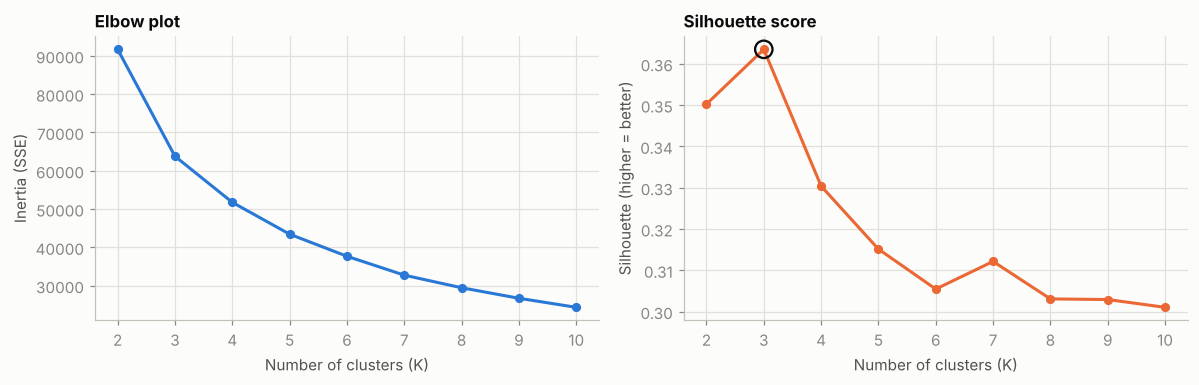

Highest silhouette at K = 3


In [11]:
rows = []
for k in range(2, 11):
    m = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    rows.append({"k": k, "inertia": m.inertia_,
                 "silhouette": silhouette_score(X, m.labels_, sample_size=5000, random_state=SEED),
                 "davies_bouldin": davies_bouldin_score(X, m.labels_),
                 "calinski_harabasz": calinski_harabasz_score(X, m.labels_)})
k_scan = pd.DataFrame(rows).set_index("k")
display(k_scan.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(k_scan.index, k_scan["inertia"], color=BLUE, linewidth=2, marker="o", markersize=5)
axes[0].set_title("Elbow plot")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia (SSE)")
axes[1].plot(k_scan.index, k_scan["silhouette"], color=ORANGE, linewidth=2, marker="o", markersize=5)
best_k = k_scan["silhouette"].idxmax()
axes[1].scatter([best_k], [k_scan.loc[best_k, "silhouette"]], s=130, facecolor="none", edgecolor=INK, linewidth=1.5, zorder=5)
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette (higher = better)")
for ax in axes:
    ax.set_xticks(k_scan.index)
plt.tight_layout()
plt.show()
print("Highest silhouette at K =", best_k)

### Reading the K scan

The silhouette peaks at K = 3 (0.363), ahead of K = 2 (0.350) and K = 4 (0.330). The Calinski-Harabasz score, which rewards compact and well-separated clusters, also peaks at 3. The elbow plot has no sharp corner, but the biggest single drop in SSE is from 2 to 3 clusters (about 30%), and every step after that buys less (about 19% for 3 to 4, 16% for 4 to 5). The Davies-Bouldin score is the odd one out. It keeps creeping down as K grows (0.971 at K = 3, 0.910 at K = 9), so it doesn't point to any particular K.

Taken together, K = 3 holds up, so I'm keeping my original choice. It is also the easiest to explain. One caution: a silhouette of 0.36 is modest. There is real structure here, but the groups overlap instead of sitting in neat separate blobs.

## 6. What do the clusters actually mean?

Numbers like "centroid 3.44" aren't useful on their own, so I translate back to the original units. Because wage and value are so skewed, I report the **median** for those two (the mean would be dragged up by a few superstars) and the mean for the rest.

In [12]:
labels_final = sk_labels_a            # scikit-learn result, clusters numbered by 'overall' (0 = lowest)

profile = raw.assign(cluster=labels_final)
summary = profile.groupby("cluster").agg(
    players=("overall", "size"),
    avg_overall=("overall", "mean"),
    avg_potential=("potential", "mean"),
    avg_age=("age", "mean"),
    median_wage_eur=("wage_eur", "median"),
    median_value_eur=("value_eur", "median"),
).round(1)
display(summary)

top5 = (players[["short_name", "overall", "age"]].assign(cluster=labels_final)
        .sort_values("overall", ascending=False).groupby("cluster").head(5)
        .sort_values(["cluster", "overall"], ascending=[True, False]))
display(top5.set_index(["cluster", "short_name"]))

,players,avg_overall,avg_potential,avg_age,median_wage_eur,median_value_eur
cluster,,,,,,
0,7720,60.2,70.5,21.1,1000.0,600000.0
1,6607,66.5,66.9,29.8,3000.0,775000.0
2,4838,73.7,77.7,25.4,16000.0,4000000.0


overall  age
cluster short_name                       
0       Luisinho Conradi          71   21
        Alexandre Frandeira       71   21
        Jaimosa Cavaco            70   21
        Paolinho Leima            70   21
        Jonaldo Monteiro          70   21
1       G. Buffon                 80   43
        Pepe Reina                78   38
        A. Talavera               78   38
        F. Quagliarella           78   38
        B. Foster                 78   38
2       L. Messi                  93   34
        R. Lewandowski            92   32
        Cristiano Ronaldo         91   36
        Neymar Jr                 91   29
        K. De Bruyne              91   30

### Naming the clusters

Reading the table, the three groups are easy to describe:

- **Cluster 0, young prospects (7,720 players).** Average age 21 and average overall 60, but average potential 70.5, so there is about ten points of growth built in. They have the lowest pay and the lowest value of the three.
- **Cluster 1, veterans (6,607 players).** Average age almost 30, overall 66.5 and potential 66.9. There is little room left to grow, which is why potential has caught up with overall. The oldest names in the game are here (Buffon, at 43, tops the list).
- **Cluster 2, established first-team players and stars (4,838 players).** Highest on everything: overall 73.7, potential 77.7, median value 4 million euros and median wage 16,000 euros. The average age is 25.4, so these are players in or near their prime. Messi, Lewandowski, Ronaldo, Neymar and De Bruyne all landed here.

So the clustering is separating players by career stage and quality, not by how they play. That fits what the PCA shows later.

## 7. Hierarchical clustering

K-Means needs me to pick K up front. Hierarchical (agglomerative) clustering starts with every player as their own cluster and keeps merging the two closest ones until only one is left. The result is a tree called a **dendrogram**, and I choose where to cut it.

It needs a distance between every pair of players, so it gets slow and memory-hungry on 19,000 rows. I run it on a random sample of 3,000 players, and I compare it to K-Means on those same 3,000.

A "linkage" rule decides what distance between two clusters means. I try four: Ward (merge so total variance rises the least), complete (farthest pair), average, and single (nearest pair).

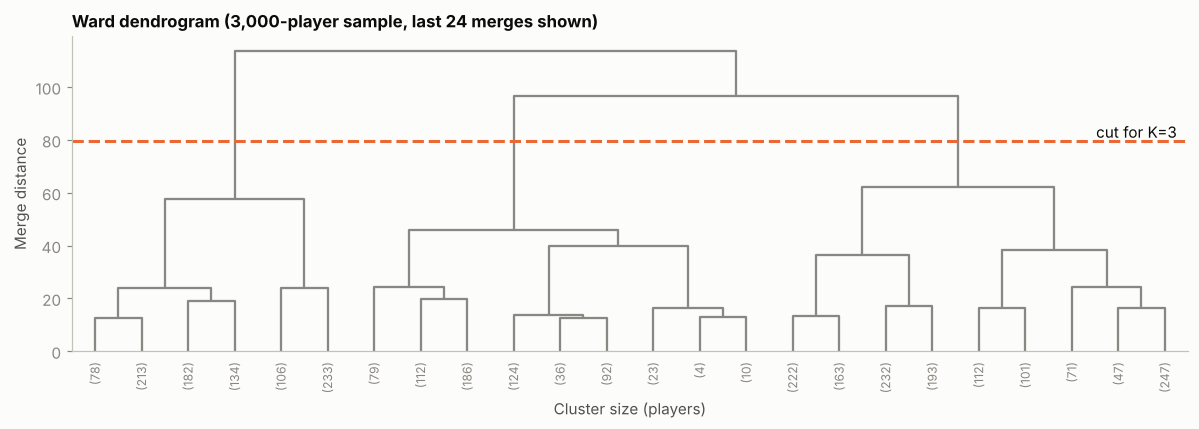

In [13]:
rng = np.random.default_rng(SEED)
idx = rng.choice(len(X), size=3000, replace=False)
Xs = X[idx]

Z = linkage(Xs, method="ward")
cut_height = (Z[-K, 2] + Z[-(K - 1), 2]) / 2      # a cut that leaves K clusters

fig, ax = plt.subplots(figsize=(11, 4))
dendrogram(Z, truncate_mode="lastp", p=24, ax=ax, color_threshold=0, above_threshold_color=MUTED,
           show_leaf_counts=True, leaf_rotation=90, leaf_font_size=8)
ax.axhline(cut_height, color=ORANGE, linestyle="--", linewidth=2)
ax.text(0.99, cut_height, f" cut for K={K}", color=INK, ha="right", va="bottom", transform=ax.get_yaxis_transform())
ax.set_title("Ward dendrogram (3,000-player sample, last 24 merges shown)")
ax.set_ylabel("Merge distance")
ax.set_xlabel("Cluster size (players)")
ax.grid(False)
plt.tight_layout()
plt.show()

In [14]:
km_sample = sk_labels[idx]
rows = []
for method in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=K, linkage=method).fit_predict(Xs)
    rows.append({"linkage": method,
                 "silhouette": round(silhouette_score(Xs, lab), 3),
                 "davies_bouldin": round(davies_bouldin_score(Xs, lab), 3),
                 "ARI vs K-Means": round(adjusted_rand_score(km_sample, lab), 3),
                 "cluster sizes": sorted(np.bincount(lab).tolist(), reverse=True)})
linkage_table = pd.DataFrame(rows).set_index("linkage")
display(linkage_table)

kmeans_on_sample = {"silhouette": round(silhouette_score(Xs, km_sample), 3),
                    "davies_bouldin": round(davies_bouldin_score(Xs, km_sample), 3)}
print("K-Means on the same 3,000 players:", kmeans_on_sample)

,silhouette,davies_bouldin,ARI vs K-Means,cluster sizes
linkage,,,,
ward,0.290,1.107,0.489,"[1388, 946, 666]"
complete,0.281,1.046,0.236,"[2225, 769, 6]"
average,0.458,0.588,0.008,"[2961, 38, 1]"
single,0.659,0.298,0.001,"[2994, 4, 2]"


K-Means on the same 3,000 players: {'silhouette': 0.36, 'davies_bouldin': 0.972}


### Reading the hierarchical results

Ward linkage is the only one that gives a usable result. It splits the 3,000 players into groups of 1,388, 946 and 666, which is a similar shape to K-Means. Agreement with K-Means is moderate (ARI 0.489): the two methods agree on the broad picture and disagree about players near the borders. That is what I'd expect when the data is one continuous cloud and not separate blobs. In the dendrogram, the last two merges happen at much larger distances (roughly 97 and 114) than the one before them (about 62), which supports a small number of groups.

The other three linkages look better on paper and aren't. Single linkage has a silhouette of 0.659 and average linkage 0.458, higher than anything else, but look at the cluster sizes: [2994, 4, 2] and [2961, 38, 1]. They just peel a few outlier superstars into tiny clusters and leave everyone else in one big lump. Complete linkage does something similar (one cluster of only 6 players). The high scores come from a few isolated points sitting far from everyone, not from useful groups. It's a reminder to check cluster sizes before trusting a single metric.

On the same 3,000 players K-Means scores 0.360 silhouette and 0.972 Davies-Bouldin, against 0.290 and 1.107 for Ward. For this data I'd stick with K-Means.

## 8. Dimensionality reduction with PCA

I've already used PCA twice just to draw pictures. Here I look at it properly. PCA finds new axes (principal components) that capture as much of the variation in the data as possible, in order. If the first two components hold most of it, a 2D picture is a fair summary. If not, the plots above hide a lot.

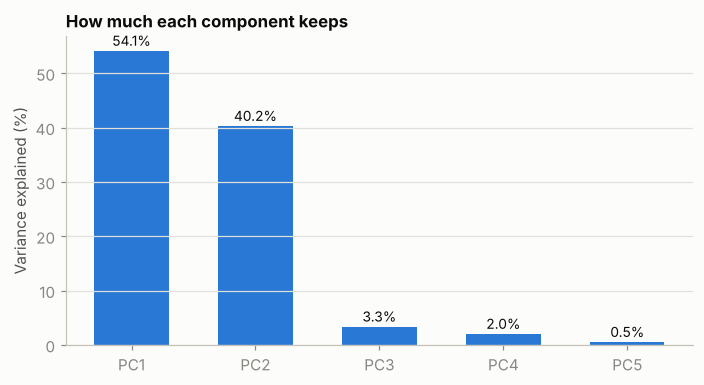

Cumulative variance: [ 54.1  94.3  97.6  99.5 100. ]

How each original feature feeds the first two components (loadings):


,PC1,PC2
overall,0.66,0.35
potential,0.21,0.70
wage_eur,0.14,0.13
value_eur,0.08,0.11
age,0.70,-0.59


In [15]:
pca = PCA().fit(X)
evr = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar([f"PC{i+1}" for i in range(len(evr))], evr * 100, color=BLUE, width=0.6)
for b, v in zip(bars, evr * 100):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.1f}%", ha="center", fontsize=9, color=INK)
ax.set_ylabel("Variance explained (%)")
ax.set_title("How much each component keeps")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print("Cumulative variance:", np.round(np.cumsum(evr) * 100, 1))
loadings = pd.DataFrame(pca.components_[:2].T, index=features, columns=["PC1", "PC2"]).round(2)
print("\nHow each original feature feeds the first two components (loadings):")
display(loadings)

ARI between K-Means on all 5 features and K-Means on only the 2 principal components: 0.985


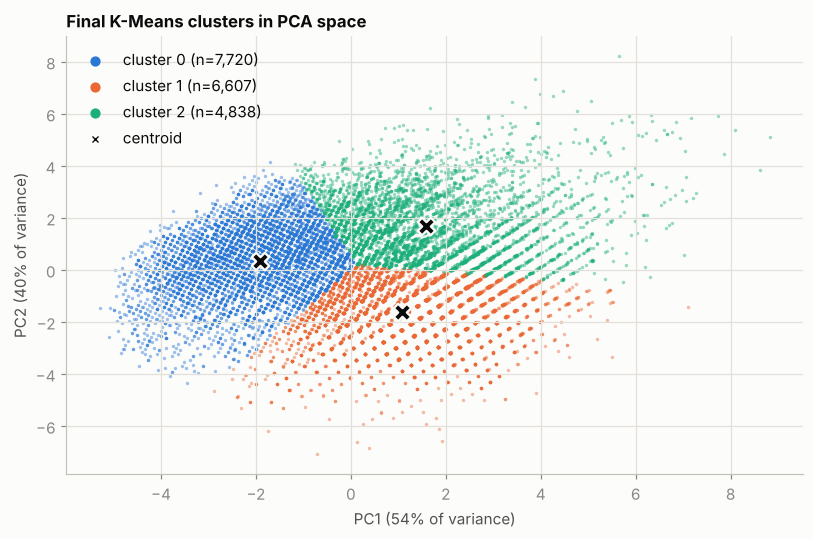

In [16]:
X2 = pca.transform(X)[:, :2]
km2 = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X2)
print("ARI between K-Means on all 5 features and K-Means on only the 2 principal components:",
      round(adjusted_rand_score(sk_labels, km2.labels_), 3))

fig, ax = plt.subplots(figsize=(7.5, 5))
cents2 = pca.transform(sk_cents.T.to_numpy())[:, :2]
names = {0: "cluster 0", 1: "cluster 1", 2: "cluster 2"}
for c in range(K):
    m = labels_final == c
    ax.scatter(X2[m, 0], X2[m, 1], s=5, alpha=0.45, color=CLUSTER_COLORS[c], linewidths=0, label=f"cluster {c} (n={m.sum():,})")
ax.scatter(cents2[:, 0], cents2[:, 1], marker="X", s=130, color=INK, edgecolor=SURFACE, linewidth=1.5, zorder=5, label="centroid")
ax.set_xlabel(f"PC1 ({evr[0]*100:.0f}% of variance)")
ax.set_ylabel(f"PC2 ({evr[1]*100:.0f}% of variance)")
ax.set_title("Final K-Means clusters in PCA space")
leg = ax.legend()
for h in leg.legend_handles:
    h.set_sizes([45])
    h.set_alpha(1)
plt.tight_layout()
plt.show()

### Reading the PCA results

The first two components keep 94.3% of the variance (PC1 54.1%, PC2 40.2%), so the 2D pictures are a fair summary of the five features. PC1 is mostly overall rating and age together (loadings 0.66 and 0.70), so a high PC1 means an older, higher-rated player. PC2 is mostly potential (0.70) against age (-0.59), so it measures upside. That matches the cluster story: young prospects on one side, veterans low on PC2, and the top tier high on both.

Running K-Means on only the two components gives almost the same clusters (ARI 0.985), so squeezing five dimensions down to two costs very little here.

Wage and value have small loadings, which I want to look into next.

### Extra check: are wage and value doing anything?

Looking at the PCA loadings, wage and value barely register. I think I know why. They are so skewed that, after min-max scaling, almost every player sits near 1 and only a few superstars reach 11. Their standard deviation is tiny next to the other features, so they hardly move the distances. To test that, I take the log of wage and value first (which squeezes the long tail), rescale the same way, and cluster again.

In [17]:
logged = raw.copy()
logged["wage_eur"] = np.log(logged["wage_eur"])
logged["value_eur"] = np.log(logged["value_eur"])
data_log = ((logged - logged.min()) / (logged.max() - logged.min())) * 10 + 1

print("Spread (std) of each scaled feature, before vs after taking logs of wage and value:")
display(pd.DataFrame({"original scaling": data.std(), "log wage & value": data_log.std()}).round(2))

km_log = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(data_log.to_numpy())
lab_log, _ = align(km_log.labels_, pd.DataFrame(km_log.cluster_centers_.T, index=features))
print("ARI vs my main clustering:", round(adjusted_rand_score(labels_final, lab_log), 3))
print("Silhouette:", round(silhouette_score(data_log.to_numpy(), km_log.labels_, sample_size=5000, random_state=SEED), 3))

log_summary = raw.assign(cluster=lab_log).groupby("cluster").agg(
    players=("overall", "size"), avg_overall=("overall", "mean"), avg_potential=("potential", "mean"),
    avg_age=("age", "mean"), median_wage_eur=("wage_eur", "median"), median_value_eur=("value_eur", "median")).round(1)
display(log_summary)

Spread (std) of each scaled feature, before vs after taking logs of wage and value:


,original scaling,log wage & value
overall,1.50,1.50
potential,1.32,1.32
wage_eur,0.56,2.08
value_eur,0.39,1.23
age,1.75,1.75


ARI vs my main clustering: 0.708


Silhouette: 0.331


,players,avg_overall,avg_potential,avg_age,median_wage_eur,median_value_eur
cluster,,,,,,
0,7462,60.2,70.6,21.1,1000.0,600000.0
1,5948,65.6,66.4,29.5,3000.0,700000.0
2,5755,73.1,76.6,26.1,15000.0,3100000.0


### What the log check shows

It confirms the suspicion. After taking logs, wage and value spread out (standard deviation 2.08 and 1.23, up from 0.56 and 0.39), so they now pull on the distances. The clustering changes: the ARI against my main result is 0.708, and the top cluster grows from 4,838 to 5,755 players. The overall story survives, though. There are still the same three kinds of group (young with high potential, older with potential used up, and a top tier) with similar averages. I can't compare the silhouette directly (0.331 here against 0.363) because the two versions are measured in different feature spaces.

I'm keeping the original scaling for the main results, because it is what my from-scratch code was built around. If I were starting again I would take logs of wage and value first.

# Part B: Model evaluation

## 9. A supervised task to evaluate

Clustering can't produce a confusion matrix or a ROC curve, because there are no true labels. To practice the evaluation tools I need a problem with an answer key.

FIFA gives me a natural one: **a player's position**. I'll predict whether an outfield player is a defender, a midfielder or a forward, using six in-game attributes: `pace`, `shooting`, `passing`, `dribbling`, `defending` and `physic`. I group each player's first listed position like this:

- DEF: CB, LB, RB, LWB, RWB (and the left/right centre-back variants)
- MID: CDM, CM, CAM, LM, RM (and the left/right variants)
- FWD: ST, CF, LW, RW, LF, RF, LS, RS

Goalkeepers are left out. They don't have those six attributes (the columns are empty for them), and they're trivially easy to spot anyway.

In [18]:
role_map = {"CB": "DEF", "LCB": "DEF", "RCB": "DEF", "LB": "DEF", "RB": "DEF", "LWB": "DEF", "RWB": "DEF",
            "CDM": "MID", "LDM": "MID", "RDM": "MID", "CM": "MID", "LCM": "MID", "RCM": "MID",
            "CAM": "MID", "LAM": "MID", "RAM": "MID", "LM": "MID", "RM": "MID",
            "ST": "FWD", "CF": "FWD", "LW": "FWD", "RW": "FWD", "LF": "FWD", "RF": "FWD", "LS": "FWD", "RS": "FWD",
            "GK": "GK"}

skills = ["pace", "shooting", "passing", "dribbling", "defending", "physic"]

pos = players["player_positions"].str.split(",").str[0].str.strip()
unmapped = sorted(set(pos) - set(role_map))
print("Positions I did not map:", unmapped if unmapped else "none")

roles = players.assign(role=pos.map(role_map))
roles = roles[roles["role"] != "GK"].dropna(subset=skills)

X_all = roles[skills]
y_all = roles["role"]
print("Outfield players with all six attributes:", len(roles))
print("\nClass balance:")
print(y_all.value_counts().to_frame("players").assign(share=lambda d: (d["players"] / d["players"].sum()).round(3)))

Positions I did not map: none
Outfield players with all six attributes: 17041

Class balance:
      players  share
role                
MID      7009  0.411
DEF      6366  0.374
FWD      3666  0.215


The classes are not perfectly balanced, so plain accuracy can flatter a model that favours the big class. I'll watch **macro-F1** (the average F1 of the three classes, each counted equally) alongside accuracy.

I hold back 20% of the players as a **test set** that I don't touch until the very end. Everything else (training, cross-validation, tuning) happens on the other 80%. The split is stratified, meaning each part keeps the same mix of DEF, MID and FWD.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
print("train:", X_train.shape, "  test:", X_test.shape)

train: (13632, 6)   test: (3409, 6)


## 10. Cross-validation: comparing models fairly

One train/test split can be lucky or unlucky. **Stratified 5-fold cross-validation** splits the training data into 5 parts, trains on 4, scores on the 5th, and rotates until every part has been the validation set once. The mean says how well a model does, and the standard deviation says how much that depends on the split.

I compare four models:

- **Dummy**: always guesses the most common class. This is the floor any real model has to beat.
- **Logistic regression** (with scaling)
- **K-Nearest Neighbours** (with scaling, because KNN is distance-based)
- **Random forest**

Scaling lives inside a pipeline, so each fold learns its scaling only from its own training part. Doing it earlier would leak information from the validation fold.

,accuracy,accuracy_sd,macro_F1,macro_F1_sd,ROC_AUC,ROC_AUC_sd
model,,,,,,
Dummy (most frequent),0.411,0.000,0.194,0.000,0.500,0.000
Logistic regression,0.828,0.006,0.827,0.006,0.950,0.002
KNN (k=15),0.828,0.009,0.825,0.009,0.946,0.003
Random forest,0.832,0.004,0.830,0.004,0.951,0.003


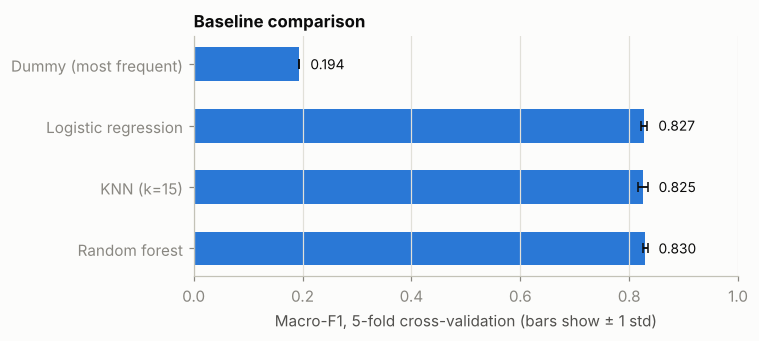

In [20]:
models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression":   make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN (k=15)":            make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "Random forest":         RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro", "roc_auc": "roc_auc_ovr"}

rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"model": name,
                 "accuracy": res["test_accuracy"].mean(), "accuracy_sd": res["test_accuracy"].std(),
                 "macro_F1": res["test_f1_macro"].mean(), "macro_F1_sd": res["test_f1_macro"].std(),
                 "ROC_AUC": res["test_roc_auc"].mean(), "ROC_AUC_sd": res["test_roc_auc"].std()})
cv_table = pd.DataFrame(rows).set_index("model")
display(cv_table.round(3))

fig, ax = plt.subplots(figsize=(7, 3.2))
ypos = np.arange(len(cv_table))[::-1]
ax.barh(ypos, cv_table["macro_F1"], xerr=cv_table["macro_F1_sd"], color=BLUE, height=0.55,
        error_kw={"ecolor": INK, "elinewidth": 1.2, "capsize": 3})
for y, v, sd in zip(ypos, cv_table["macro_F1"], cv_table["macro_F1_sd"]):
    ax.text(v + sd + 0.02, y, f"{v:.3f}", va="center", fontsize=9, color=INK)
ax.set_yticks(ypos)
ax.set_yticklabels(cv_table.index)
ax.set_xlim(0, 1)
ax.set_xlabel("Macro-F1, 5-fold cross-validation (bars show ± 1 std)")
ax.set_title("Baseline comparison")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Reading the cross-validation results

The dummy model always answers "midfielder", the most common class. It gets 41.1% accuracy but a macro-F1 of only 0.194, and that is the floor every real model has to beat.

All three real models land together at about 83% accuracy, macro-F1 between 0.825 and 0.830, and ROC-AUC between 0.946 and 0.951. The random forest is nominally first, but its lead over logistic regression is 0.003 in macro-F1 while the fold-to-fold standard deviation is 0.004 to 0.009. So I can't say from this that any one of them is better than the others.

It surprised me a little that plain logistic regression, which draws straight boundaries, keeps up with a random forest. My guess is that the six attributes separate the positions in a fairly simple way, and that the limit is the information in the data and not how flexible the model is.

## 11. Hyperparameter tuning

Hyperparameters are the settings I choose before training, such as the number of neighbours in KNN. `GridSearchCV` tries every combination in a grid, scores each one with the same 5-fold cross-validation, and keeps the best. I score on macro-F1. The search only sees the training data. The test set stays locked away.

I tune the three real models (not the Dummy).

In [21]:
grids = {
    "Logistic regression": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                            {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "KNN (k=15)":          (make_pipeline(StandardScaler(), KNeighborsClassifier()),
                            {"kneighborsclassifier__n_neighbors": [5, 11, 21, 31, 51, 81, 121],
                             "kneighborsclassifier__weights": ["uniform", "distance"]}),
    "Random forest":       (RandomForestClassifier(random_state=SEED, n_jobs=1),
                            {"n_estimators": [100, 300], "max_depth": [6, 10, 16, None], "min_samples_leaf": [1, 3, 8]}),
}

tuned, rows = {}, []
for name, (estimator, grid) in grids.items():
    search = GridSearchCV(estimator, grid, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    tuned[name] = search
    rows.append({"model": name.replace(" (k=15)", ""),
                 "macro_F1 before tuning (CV)": cv_table.loc[name, "macro_F1"],
                 "macro_F1 after tuning (CV)": search.best_score_,
                 "combinations tried": len(search.cv_results_["params"]),
                 "best settings": {k.split("__")[-1]: v for k, v in search.best_params_.items()}})
tuning_table = pd.DataFrame(rows).set_index("model")
pd.set_option("display.max_colwidth", 120)
display(tuning_table.round(4))

,macro_F1 before tuning (CV),macro_F1 after tuning (CV),combinations tried,best settings
model,,,,
Logistic regression,0.8274,0.8278,5,{'C': 10}
KNN,0.8253,0.8294,14,"{'n_neighbors': 51, 'weights': 'distance'}"
Random forest,0.8298,0.8341,24,"{'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 300}"


### Reading the tuning results

Tuning helped a little and no more. Cross-validated macro-F1 moved from 0.8274 to 0.8278 for logistic regression, from 0.8253 to 0.8294 for KNN and from 0.8298 to 0.8341 for the random forest, so the gains are at most about 0.004. The winning settings were C = 10 for logistic regression, 51 neighbours with distance weighting for KNN (a smoother model than the 15 I started with), and for the forest 300 trees, no depth limit and at least 3 players per leaf.

I first capped the KNN grid at 51 neighbours, and since 51 won I widened it to 81 and 121 to make sure it wasn't just the edge of my grid. It still picked 51, so that one is a real optimum. The forest's 300 trees is at the top of its grid, but more trees rarely hurt accuracy, they only cost run time.

The small gains are the main lesson here. All three models were already close to the ceiling, and better settings can't add information that isn't in the six features.

## 12. The final exam: the held-out test set

Now, once, I score the models on the 20% they have never seen. I include the Dummy as the floor. Because the tuned models were picked using cross-validation on the training data only, this score is an honest estimate of how they would do on new players.

In [22]:
final_models = {"Dummy (most frequent)": models["Dummy (most frequent)"].fit(X_train, y_train)}
for name, search in tuned.items():
    final_models[name.replace(" (k=15)", "") + " (tuned)"] = search.best_estimator_

rows = []
for name, model in final_models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "macro_F1": f1_score(y_test, pred, average="macro"),
                 "ROC_AUC (one-vs-rest)": roc_auc_score(y_test, proba, multi_class="ovr", average="macro", labels=model.classes_)})
test_table = pd.DataFrame(rows).set_index("model")
display(test_table.round(3))

winner_name = test_table.drop(index="Dummy (most frequent)")["macro_F1"].idxmax()
winner = final_models[winner_name]
print("Best model on the test set:", winner_name)

,accuracy,macro_F1,ROC_AUC (one-vs-rest)
model,,,
Dummy (most frequent),0.411,0.194,0.500
Logistic regression (tuned),0.831,0.829,0.948
KNN (tuned),0.835,0.832,0.951
Random forest (tuned),0.837,0.834,0.953


Best model on the test set: Random forest (tuned)


## 13. A closer look at the winner

**Confusion matrix.** Rows are the true position and columns are what the model predicted. The diagonal is correct answers. Everything off the diagonal is a specific mix-up, so it tells me *which* positions the model confuses, which a single accuracy number hides.

**Precision, recall, F1.** For one class, say FWD:
- *Precision*: of the players the model called FWD, how many really were? (How trustworthy is the label?)
- *Recall*: of all the real FWDs, how many did the model find? (How many did it miss?)
- *F1*: the balance of the two (their harmonic mean).

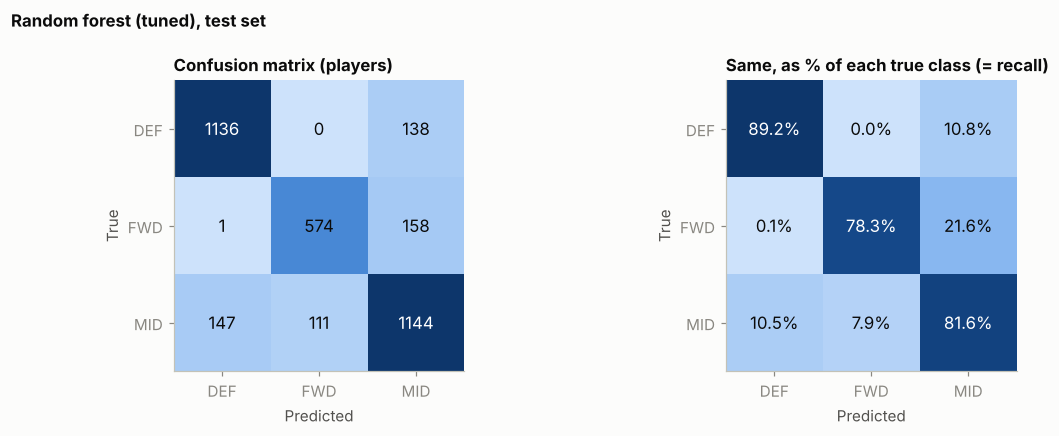

,pred DEF,pred FWD,pred MID
true DEF,1136,0,138
true FWD,1,574,158
true MID,147,111,1144


,precision,recall,f1-score,support
DEF,0.885,0.892,0.888,1274.000
FWD,0.838,0.783,0.810,733.000
MID,0.794,0.816,0.805,1402.000
accuracy,0.837,0.837,0.837,0.837
macro avg,0.839,0.830,0.834,3409.000
weighted avg,0.838,0.837,0.837,3409.000


In [23]:
classes = list(winner.classes_)
y_pred = winner.predict(X_test)
cm = confusion_matrix(y_test, y_pred, labels=classes)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

from matplotlib.colors import LinearSegmentedColormap
seq = LinearSegmentedColormap.from_list("blue_seq", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
for ax, mat, title, fmt in [(axes[0], cm, "Confusion matrix (players)", "{:.0f}"),
                            (axes[1], cm_pct, "Same, as % of each true class (= recall)", "{:.1f}%")]:
    ax.imshow(mat, cmap=seq, vmin=0, vmax=mat.max())
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    ax.grid(False)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, fmt.format(mat[i, j]), ha="center", va="center",
                    color="white" if mat[i, j] > 0.55 * mat.max() else INK, fontsize=11)
plt.suptitle(f"{winner_name}, test set", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

display(pd.DataFrame(cm, index=[f"true {c}" for c in classes], columns=[f"pred {c}" for c in classes]))
report = pd.DataFrame(classification_report(y_test, y_pred, labels=classes, output_dict=True)).T
display(report.round(3))

**ROC curves and AUC.** A model gives each player a probability for each position. A ROC curve asks what happens as I move the decision threshold: how many true positives I catch (y-axis) against how many false alarms I raise (x-axis). The diagonal is a coin flip. The closer the curve hugs the top-left corner, the better. **AUC** is the area under the curve: 0.5 is random, 1.0 is perfect. With three classes I draw one curve per class, each class against all the others ("one-vs-rest").

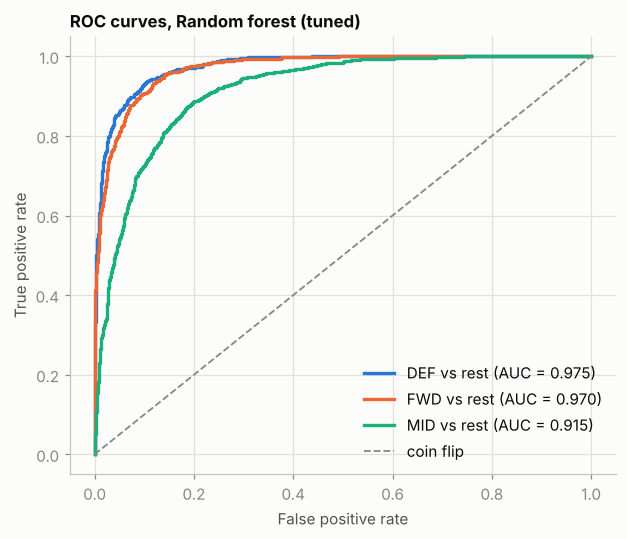

,AUC (class vs rest)
DEF,0.975
FWD,0.970
MID,0.915


In [24]:
proba = winner.predict_proba(X_test)
y_bin = label_binarize(y_test, classes=classes)

fig, ax = plt.subplots(figsize=(5.8, 5))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
    auc_c = roc_auc_score(y_bin[:, i], proba[:, i])
    ax.plot(fpr, tpr, color=CLUSTER_COLORS[i], linewidth=2.2, label=f"{c} vs rest (AUC = {auc_c:.3f})")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1.2, label="coin flip")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title(f"ROC curves, {winner_name}")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

auc_table = pd.Series({c: roc_auc_score(y_bin[:, i], proba[:, i]) for i, c in enumerate(classes)}, name="AUC (class vs rest)")
display(auc_table.round(3).to_frame())

**Which attributes matter?** Permutation importance shuffles one feature at a time on the test set and measures how much the macro-F1 drops. A big drop means the model leaned on that feature.

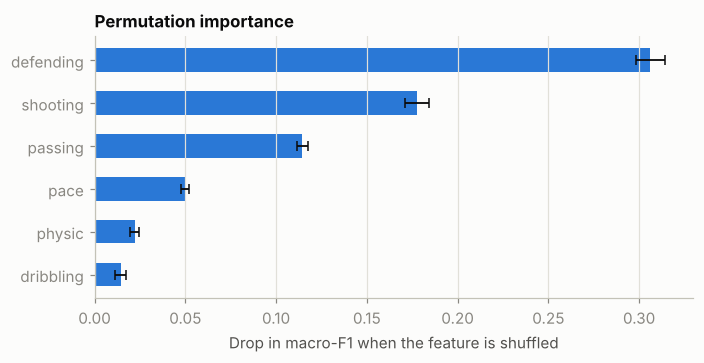

,drop_in_macro_F1,sd
feature,,
defending,0.306,0.008
shooting,0.178,0.007
passing,0.114,0.003
pace,0.050,0.002
physic,0.022,0.003
dribbling,0.014,0.003


In [25]:
imp = permutation_importance(winner, X_test, y_test, scoring="f1_macro", n_repeats=10, random_state=SEED)
imp_df = pd.DataFrame({"feature": skills, "drop_in_macro_F1": imp.importances_mean, "sd": imp.importances_std})
imp_df = imp_df.sort_values("drop_in_macro_F1")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.barh(imp_df["feature"], imp_df["drop_in_macro_F1"], xerr=imp_df["sd"], color=BLUE, height=0.55,
        error_kw={"ecolor": INK, "elinewidth": 1.2, "capsize": 3})
ax.set_xlabel("Drop in macro-F1 when the feature is shuffled")
ax.set_title("Permutation importance")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
display(imp_df.sort_values("drop_in_macro_F1", ascending=False).round(3).set_index("feature"))

### Reading the final evaluation

**Test results.** The tuned random forest comes out on top: accuracy 0.837, macro-F1 0.834 and ROC-AUC 0.953. The tuned KNN (0.835 / 0.832 / 0.951) and logistic regression (0.831 / 0.829 / 0.948) are right behind. With 3,409 test players, accuracy has a margin of error of roughly 0.6 percentage points (one standard error), so the three models are practically tied. I'd pick the forest because it was best in both cross-validation and the test, but I wouldn't claim it is clearly better. Its test macro-F1 (0.834) is the same as its cross-validation score (0.834), which suggests I didn't overfit while tuning.

**Where it goes wrong.** The confusion matrix has a clear pattern: nearly all the errors involve midfielders. Of 1,274 true defenders, 1,136 were right and the other 138 were called midfielders. Not one was called a forward. Of 733 forwards, 574 were right, 158 were called midfielders and just 1 a defender. So the model almost never mixes up a defender with a forward, which makes sense because they play at opposite ends of the pitch. Midfielders (1,402) get pulled both ways: 147 went to DEF and 111 to FWD. The ROC curves show the same thing. The AUC is 0.975 for DEF and 0.970 for FWD but only 0.915 for MID.

In precision and recall terms, defenders are the easiest (precision 0.885, recall 0.892, F1 0.888). Forwards have good precision (0.838) but lower recall (0.783): when the model says forward it is usually right, but it misses about one in five real forwards, probably wingers and attacking midfielders who look like midfielders on paper. Midfielders have the lowest precision (0.794), because the uncertain cases end up in that class.

**What it relies on.** Shuffling `defending` costs the most (macro-F1 drops by 0.306), then `shooting` (0.178) and `passing` (0.114). `pace` (0.050), `physic` (0.022) and `dribbling` (0.014) matter much less. That agrees with football common sense: a low defending score is what separates attackers from defenders. Dribbling looks unimportant, but that doesn't mean dribbling is irrelevant. It is correlated with passing, shooting and pace, so when one of them is shuffled the others cover for it.

One more thing to keep in mind: the position labels come from each player's first listed position, and plenty of players are listed at several. Some of the "mistakes" are probably label noise, so the real ceiling for this task is below 100%.

# Summary

**Clustering.** K = 3 was a sound choice (best silhouette at 0.363, and the best Calinski-Harabasz score). The three clusters are young prospects, veterans and established first-team players, so the data separates mostly by career stage and quality. My from-scratch K-Means with the ordinary mean reproduces scikit-learn almost exactly (ARI 0.997). My original geometric-mean version is a bit worse (ARI 0.733, SSE about 3% higher) because it doesn't truly minimise SSE. Hierarchical clustering with Ward linkage broadly agrees with K-Means (ARI 0.489 on a 3,000-player sample), while the other linkages produce lopsided clusters that fool the silhouette score. PCA shows two components keep 94.3% of the variance.

**Evaluation.** Predicting an outfield player's position from six attributes works well: about 83.7% accuracy, macro-F1 0.834 and ROC-AUC 0.953 on 3,409 players the model never saw, against 41.1% accuracy for always guessing midfielder. Cross-validation showed that logistic regression, KNN and random forest are practically tied, and tuning added at most about 0.004 of macro-F1. Nearly all the mistakes involve midfielders, who sit between defenders and forwards.

## Things I'd do differently

- **Skewed features.** Wage and value are so skewed that, with min-max scaling, they barely influence the main clustering. Taking logs first changes the result noticeably (ARI 0.708 between the two versions). Next time I'd log them from the start.
- **Blurry borders.** K-Means likes round clusters of similar size. This data is one continuous cloud (silhouette around 0.36), so the borders between clusters are fuzzy and shouldn't be over-read.
- **Hierarchical on a sample.** I only ran it on 3,000 of the 19,165 players because of the memory it needs, so those numbers are rougher.
- **One test split.** The final score comes from a single train/test split. Repeating it with several seeds, or repeated cross-validation, would give tighter error bars.
- **Fuzzy labels.** Positions come from each player's first listed position, and goalkeepers were left out.
- **Two separate halves.** Part B uses different features from Part A. A natural next step would be to cluster the players on the six attributes and check whether the clusters recover the positions.
- **Game data.** These are FIFA ratings, not real match statistics, so the conclusions are about the game's database.